## 1. Import Neccssay Libraries

In [170]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
)

from datetime import datetime

## 2. Import Dataset

In [171]:
bc_data = load_breast_cancer()


In [172]:
bc_data_df = pd.DataFrame(bc_data["data"], columns=bc_data["feature_names"])

bc_data_df["target"] = bc_data["target"]
bc_data_df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


## 3. Data Understanding

## 4. Data Preperation

In [173]:
X = bc_data_df.drop(labels=["target"], axis=1)

In [174]:
std_scalar = StandardScaler()

In [175]:
X = pd.DataFrame(std_scalar.fit_transform(X))

In [176]:
y = bc_data_df.target

## 5. Model Building

In [177]:
X_train, X_test, y_train, y_test =  train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [178]:
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

X_train: (455, 30)
y_train: (455,)
X_test: (114, 30)
y_test: (114,)


In [179]:
dt_classifier = DecisionTreeClassifier()

## 6. Model Training

In [180]:
%%time
dt_classifier.fit(X_train, y_train)


CPU times: total: 0 ns
Wall time: 4.16 ms


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

## 7. Model Testing || 8. Model Evaluation

#### 7.1 Training Data

In [181]:
y_pred_train = dt_classifier.predict(X_train)
print(f"Confustion Matrix:\n {confusion_matrix(y_train, y_pred_train)}")
print("--------------------------")
print(f"Accuarcy Score: {accuracy_score(y_train, y_pred_train)}")
print("--------------------------")
print(f"Precision Score: {precision_score(y_train, y_pred_train)}")
print("--------------------------")
print(f"Recal Score: {recall_score(y_train, y_pred_train)}")
print("--------------------------")
print(f"Classification Report: {classification_report(y_train, y_pred_train)}")

Confustion Matrix:
 [[170   0]
 [  0 285]]
--------------------------
Accuarcy Score: 1.0
--------------------------
Precision Score: 1.0
--------------------------
Recal Score: 1.0
--------------------------
Classification Report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00       170
           1       1.00      1.00      1.00       285

    accuracy                           1.00       455
   macro avg       1.00      1.00      1.00       455
weighted avg       1.00      1.00      1.00       455



In [182]:
y_pred_test = dt_classifier.predict(X_test)
print(f"Confustion Matrix:\n {confusion_matrix(y_test, y_pred_test)}")
print("--------------------------")
print(f"Accuarcy Score: {accuracy_score(y_test, y_pred_test)}")
print("--------------------------")
print(f"Precision Score: {precision_score(y_test, y_pred_test)}")
print("--------------------------")
print(f"Recal Score: {recall_score(y_test, y_pred_test)}")
print("--------------------------")
print(f"Classification Report: {classification_report(y_test, y_pred_test)}")

Confustion Matrix:
 [[38  4]
 [ 8 64]]
--------------------------
Accuarcy Score: 0.8947368421052632
--------------------------
Precision Score: 0.9411764705882353
--------------------------
Recal Score: 0.8888888888888888
--------------------------
Classification Report:               precision    recall  f1-score   support

           0       0.83      0.90      0.86        42
           1       0.94      0.89      0.91        72

    accuracy                           0.89       114
   macro avg       0.88      0.90      0.89       114
weighted avg       0.90      0.89      0.90       114



==========================================================================================================

## Applying PCA for Reducing Dimensions

⭐ before applying the dimensionality reduction all the featus shoudl need to be in one scale that is one unit, so it is compulaory to apply the Standard scalar before applying PCA

here i have already did the scandard scalar before

In [183]:
from sklearn.decomposition import PCA

In [184]:
pca_decomposition = PCA(n_components=2, random_state=42)
X_transformed = pca_decomposition.fit_transform(X)
X_transformed_df = pd.DataFrame(data= X_transformed, columns=["X1", "X2"])
X_transformed_df

,X1,X2
0,9.192837,1.948583
1,2.387802,-3.768172
2,5.733896,-1.075174
3,7.122953,10.275589
4,3.935302,-1.948072
...,...,...
564,6.439315,-3.576817
565,3.793382,-3.584048
566,1.256179,-1.902297
567,10.374794,1.672010


In [185]:
pca_explained_ratio = pca_decomposition.explained_variance_ratio_
print(pca_explained_ratio * 100)

[44.27202561 18.97118204]


In [186]:
import numpy as np

np.cumsum(np.round(a=pca_explained_ratio, decimals=4) * 100)


array([44.27, 63.24])

### Model Building

In [187]:
X_train, X_test, y_train, y_test =  train_test_split(X_transformed_df, y, test_size=0.2, stratify=y, random_state=42)

In [188]:
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

X_train: (455, 2)
y_train: (455,)
X_test: (114, 2)
y_test: (114,)


In [189]:
dt_classifier = DecisionTreeClassifier()

In [190]:
%%time
dt_classifier.fit(X_train, y_train)


CPU times: total: 0 ns
Wall time: 1.77 ms


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [191]:
y_pred_train = dt_classifier.predict(X_train)
print(f"Confustion Matrix:\n {confusion_matrix(y_train, y_pred_train)}")
print("--------------------------")
print(f"Accuarcy Score: {accuracy_score(y_train, y_pred_train)}")
print("--------------------------")
print(f"Precision Score: {precision_score(y_train, y_pred_train)}")
print("--------------------------")
print(f"Recal Score: {recall_score(y_train, y_pred_train)}")
print("--------------------------")
print(f"Classification Report: {classification_report(y_train, y_pred_train)}")

Confustion Matrix:
 [[170   0]
 [  0 285]]
--------------------------
Accuarcy Score: 1.0
--------------------------
Precision Score: 1.0
--------------------------
Recal Score: 1.0
--------------------------
Classification Report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00       170
           1       1.00      1.00      1.00       285

    accuracy                           1.00       455
   macro avg       1.00      1.00      1.00       455
weighted avg       1.00      1.00      1.00       455



In [192]:
y_pred_test = dt_classifier.predict(X_test)
print(f"Confustion Matrix:\n {confusion_matrix(y_test, y_pred_test)}")
print("--------------------------")
print(f"Accuarcy Score: {accuracy_score(y_test, y_pred_test)}")
print("--------------------------")
print(f"Precision Score: {precision_score(y_test, y_pred_test)}")
print("--------------------------")
print(f"Recal Score: {recall_score(y_test, y_pred_test)}")
print("--------------------------")
print(f"Classification Report: {classification_report(y_test, y_pred_test)}")

Confustion Matrix:
 [[38  4]
 [ 6 66]]
--------------------------
Accuarcy Score: 0.9122807017543859
--------------------------
Precision Score: 0.9428571428571428
--------------------------
Recal Score: 0.9166666666666666
--------------------------
Classification Report:               precision    recall  f1-score   support

           0       0.86      0.90      0.88        42
           1       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114



### Visualization

In [193]:
import matplotlib.pyplot as plt

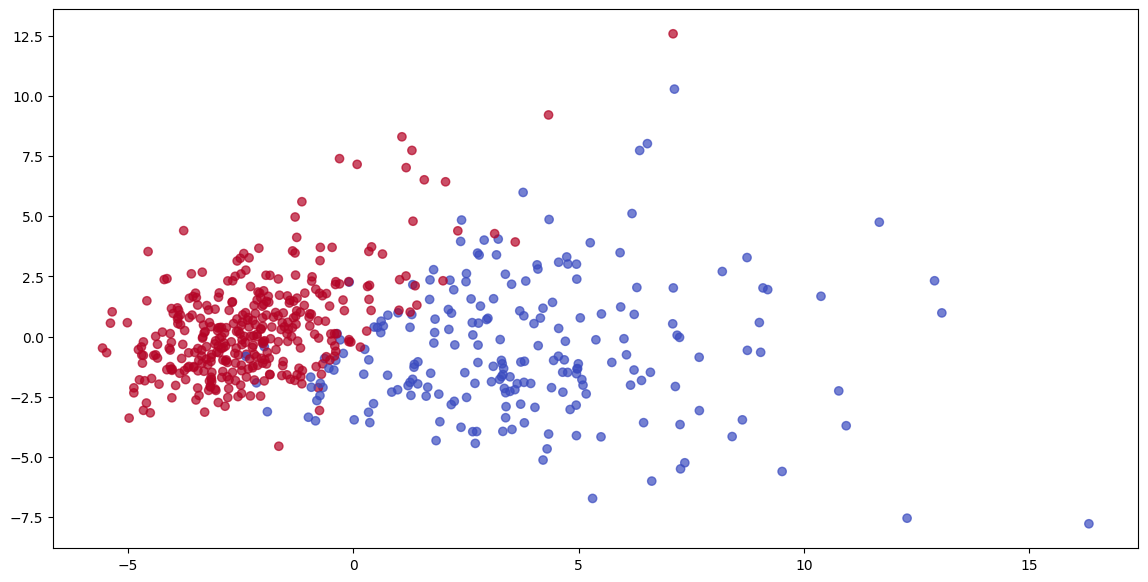

In [204]:
plt.figure(figsize=(14,7))
plt.scatter(X_transformed_df["X1"], X_transformed_df["X2"], c=y, cmap="coolwarm", alpha=0.7)
plt.show()